Quantum Billiards.

A Gaussian Wave Packet in a square box to start out with. We keep track of its probability density after a certain amount of time.

0.9999999999999998


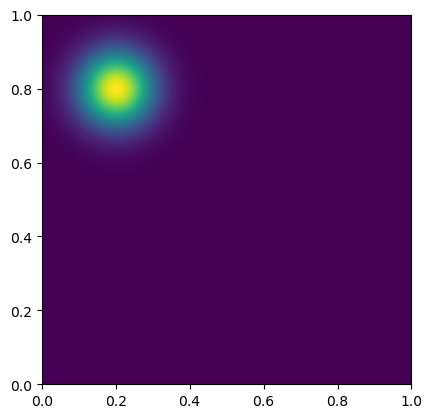

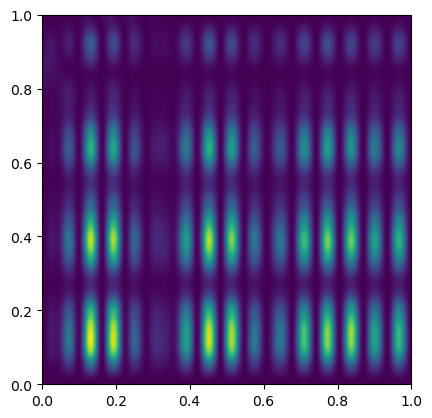

/var/folders/l7/lq1sz81j4gvdzn1xvt1mlqfc0000gn/T/ipykernel_85206/1993934436.py:77: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure()


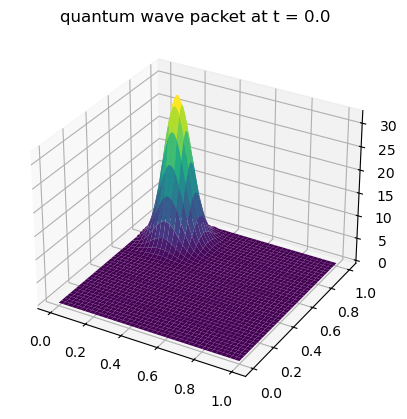

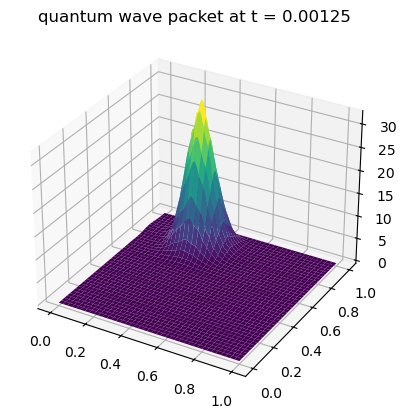

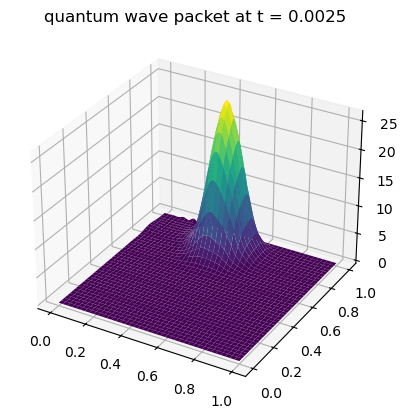

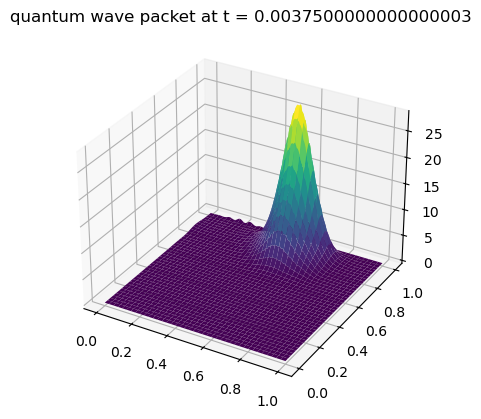

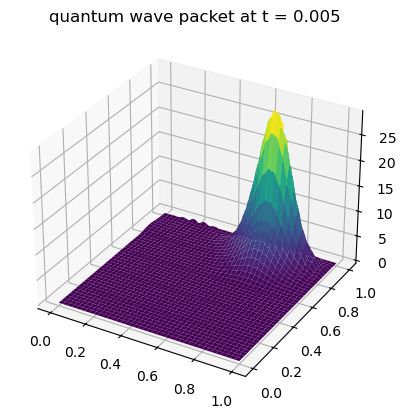

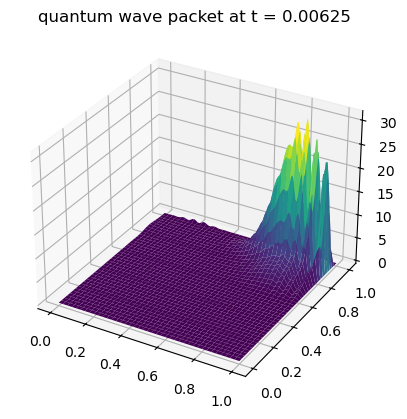

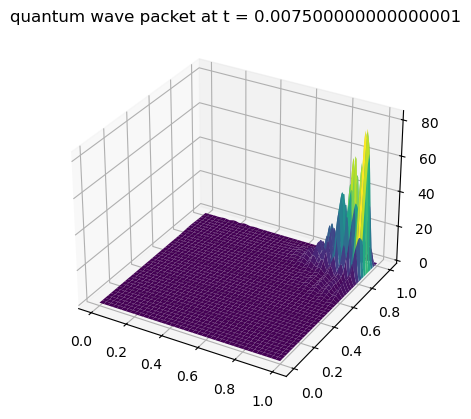

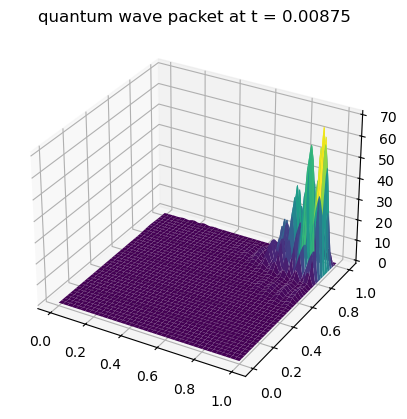

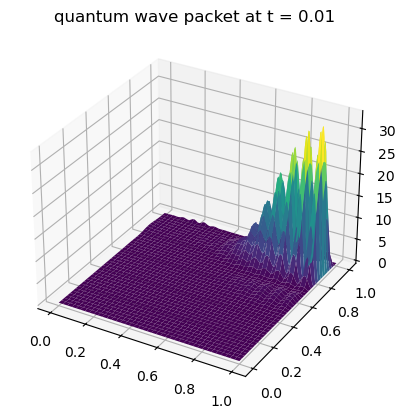

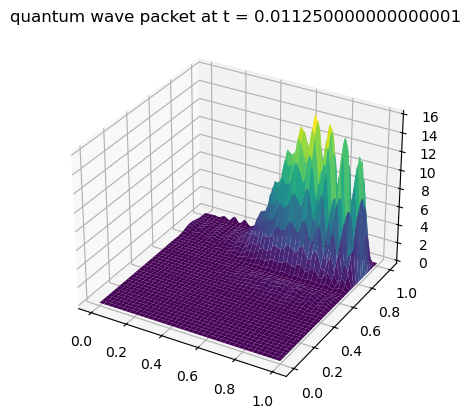

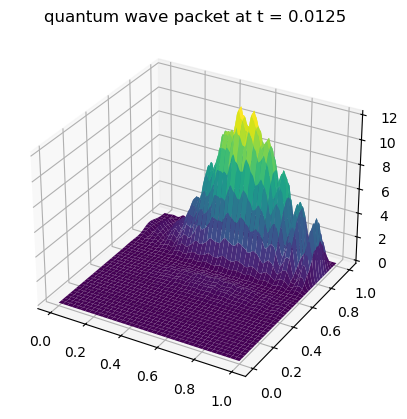

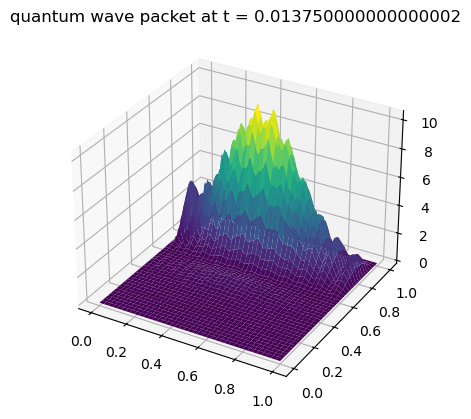

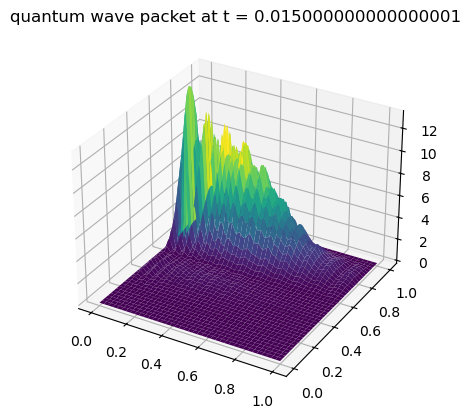

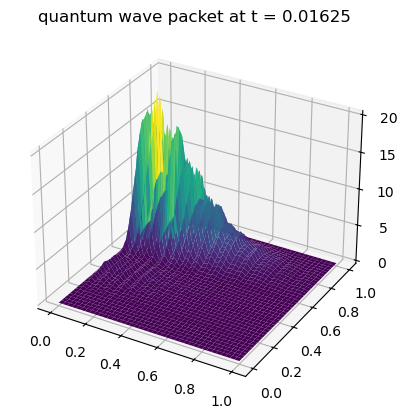

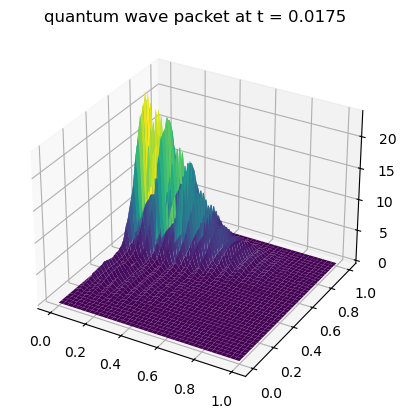

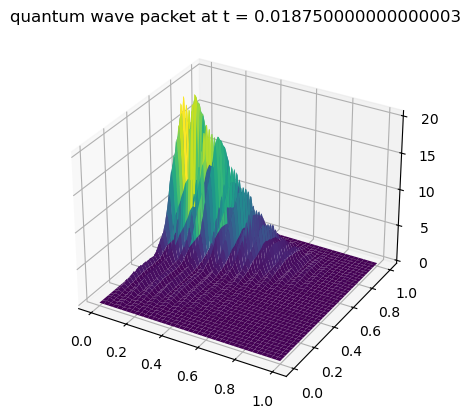

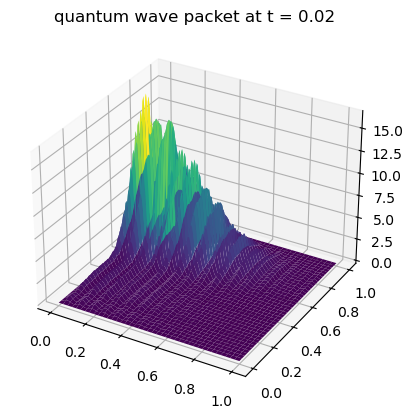

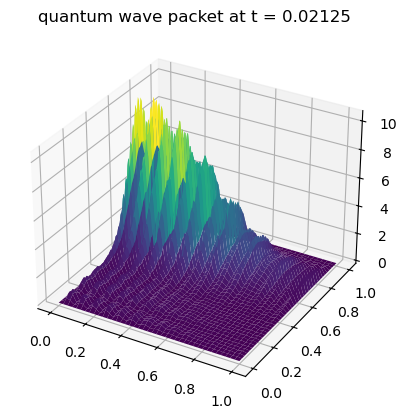

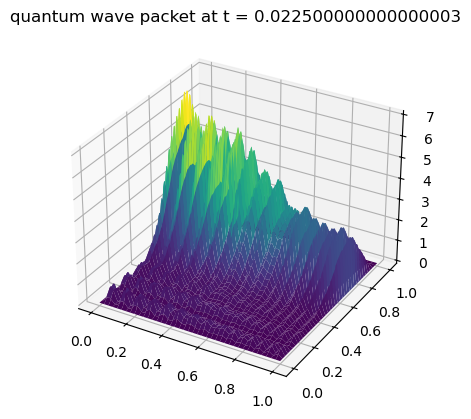

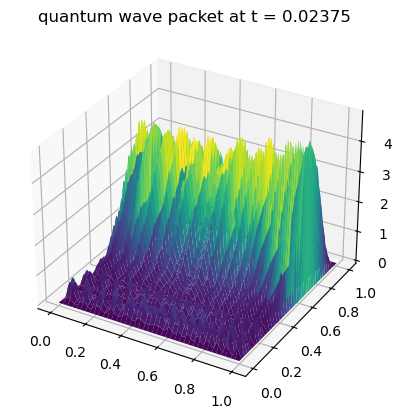

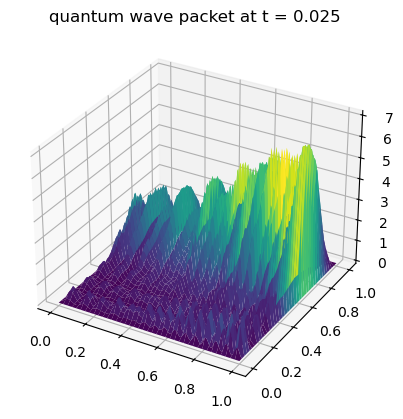

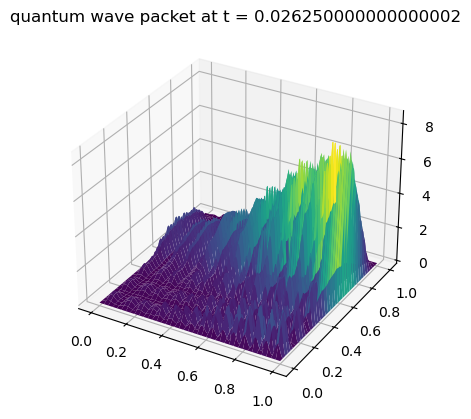

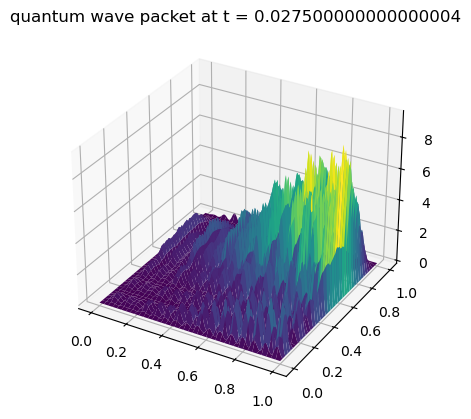

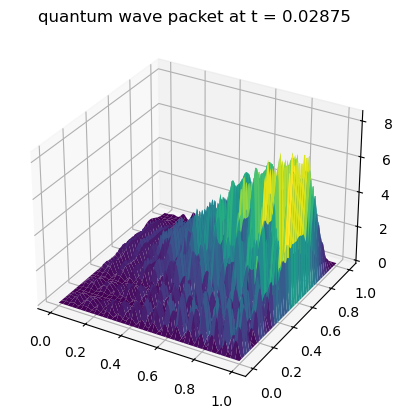

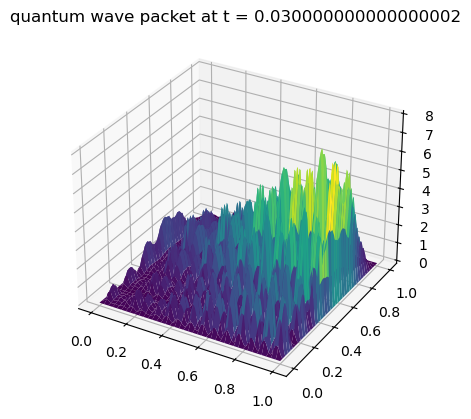

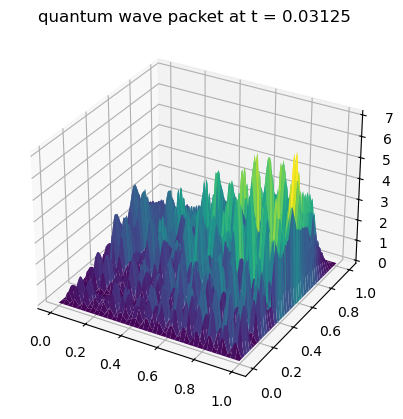

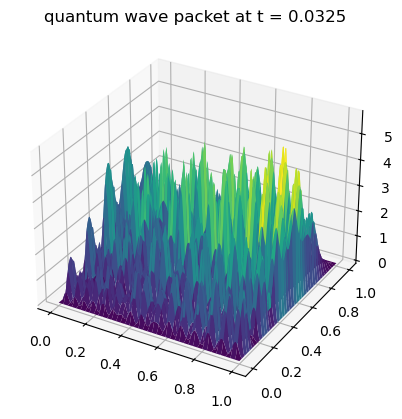

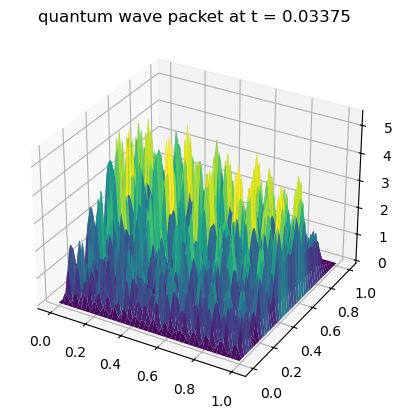

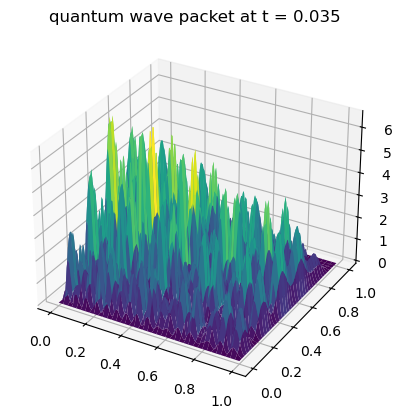

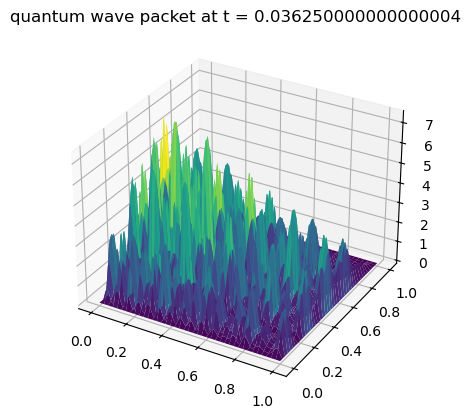

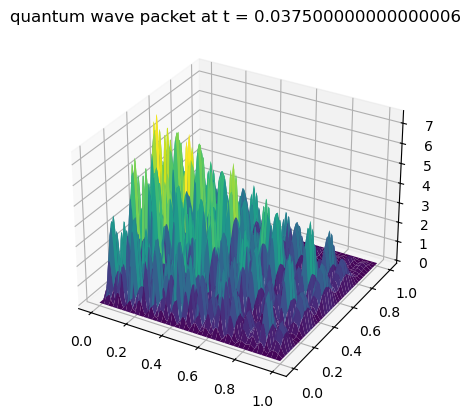

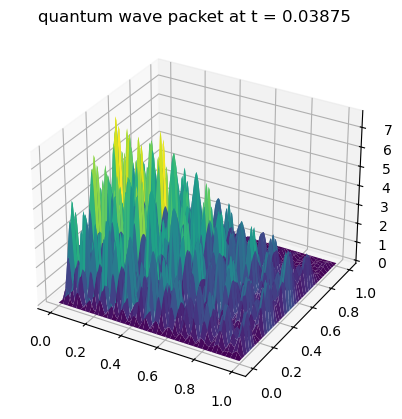

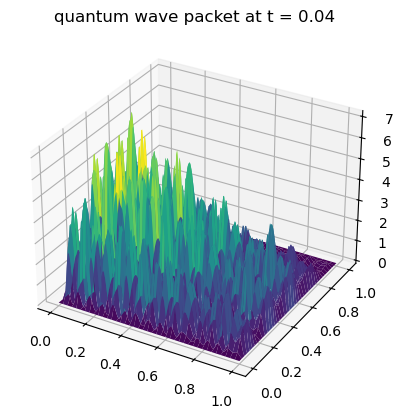

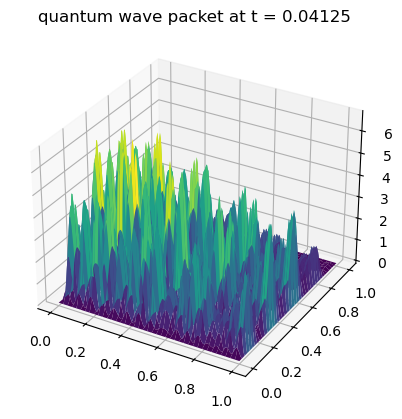

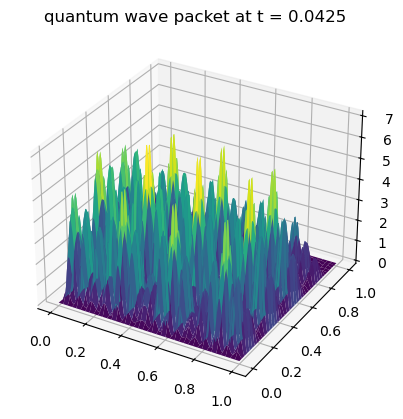

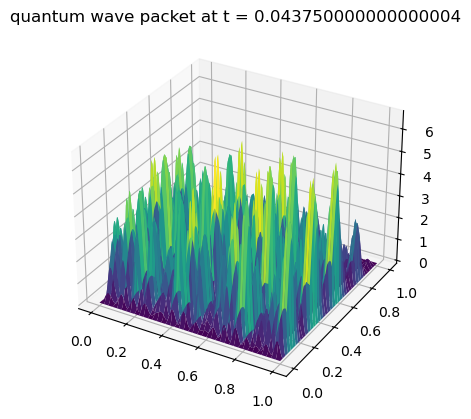

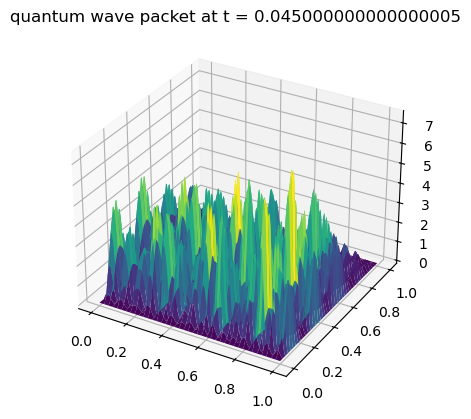

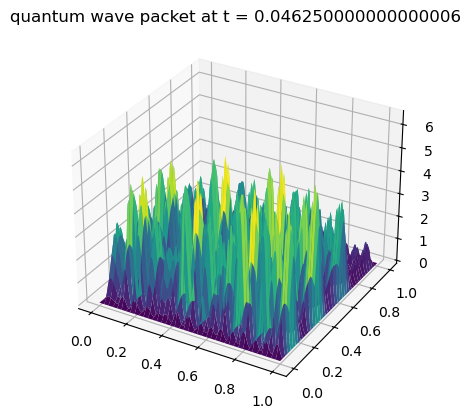

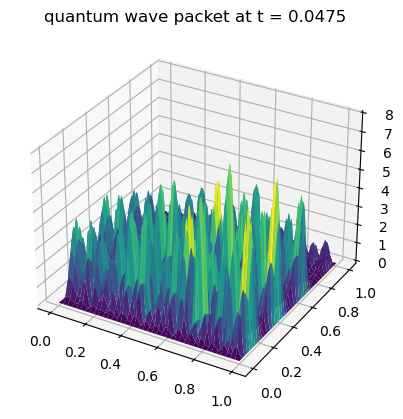

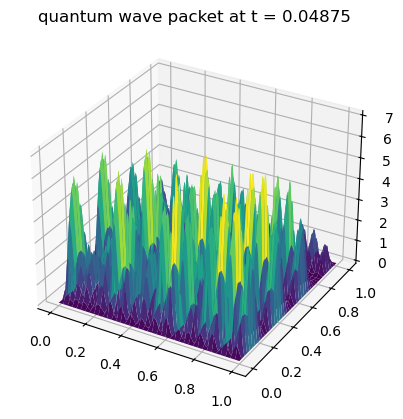

In [110]:
import numpy as np
import matplotlib.pyplot as plt

#Constants for the wave packet
sigma = 0.1 #sigma of the Gaussian wave packet
A = 1 / (2 * sigma**2)  #width of the Gaussian wave packet
#The wavelength has to be larger enough compared to delta_x and delta_y but small enough compared to the grid
k0 = 50
theta = np.radians(10)
k0x = k0 * np.cos(theta) #initial momentum of the wave packet in x direction, units:
k0y = k0 * np.sin(theta)#initial momentum of the wave packet in y direction, units:

x0,y0 = 0.20, 0.80 #Initial position

#Constants for grid and iterations etc
it = 20000 #Number of time steps / iterations
N = 201 #making a square grid with side length = N
delta_x = 0.005
delta_y = 0.005
delta_t = 0.1 * delta_x**2 

def InitialWave(kx,ky,x0,y0,A,x,y):
    return np.cos(kx*x + ky*y)*np.exp(-A * (x-x0)**2 - A * (y-y0)**2) , np.sin(kx*x + ky*y) * np.exp(-A * (x-x0)**2 - A * (y-y0)**2) #R, I

#Initialize the wave at t=0 over the entire grid
R = np.zeros((N,N))
I = np.zeros((N,N))
for i in range(N):
    for j in range(N):
        x = i * delta_x       
        y = j * delta_y       
        R[i,j], I[i,j] = InitialWave(k0x,k0y,x0,y0,A,x,y) #How do I want to store these? Do I intialize an array?
        
#Let's make sure that the wave is normalized
total = np.sum(R**2 + I**2) * delta_x * delta_y 
normalization_factor = 1 / total

#Normalize the wave
R = np.sqrt(normalization_factor) * R
I = np.sqrt(normalization_factor) * I
#print(np.sum(R**2 + I**2) * delta_x * delta_y)

#x and y array
x_arr = np.arange(N) * delta_x     
y_arr = np.arange(N) * delta_y

plt.figure()
plt.imshow((R**2 + I**2).T, origin = 'lower', extent = [0, x_arr[-1], 0, y_arr[-1]])
plt.show()

#Finite Difference to update the wave value
beta = (delta_t / (delta_x**2)) #defined variable for ease of debugging and simplicity
R[0,:] = 0
R[:,0] = 0
R[-1,:] = 0
R[:,0-1] = 0
#Here's a huge shortcut; We update the entire grid at the same instant using slicing because we're iterating over time

rho = [(I**2 + R**2)] 
for n in range(1,it):
    I[1:-1,1:-1] += beta * (R[2:,1:-1] + R[0:-2,1:-1] - 4*R[1:-1,1:-1] + R[1:-1,2:] + R[1:-1,0:-2])
    R[1:-1,1:-1] -= beta * (I[2:,1:-1] + I[0:-2,1:-1] - 4*I[1:-1,1:-1] + I[1:-1,2:] + I[1:-1,0:-2])
    if n%500 == 0: #Save a few probability densities to plot
        rho.append(I**2 + R**2)
rho = np.array(rho)    


plt.figure()
plt.imshow((R**2 + I**2).T, origin = 'lower', extent = [0, x_arr[-1], 0, y_arr[-1]])
plt.show()

# fig = plt.figure()
# ax = plt.axes(projection="3d")
# X, Y = np.meshgrid(x_arr, y_arr, indexing='ij')

for idx_i,i in enumerate(rho):
    fig = plt.figure()
    ax = plt.axes(projection="3d")
    plt.title(f"quantum wave packet at t = {(idx_i * 500) * delta_t}")
    X, Y = np.meshgrid(x_arr, y_arr, indexing='ij') #Use a meshgrid to create a coordinate system
    ax.plot_surface(X, Y, i, cmap='viridis')
plt.show()
    
# ax.plot_surface(X, Y, R**2 + I**2, cmap='viridis')